## Basic Setup

In [1]:
import os
import sys
from pathlib import Path

project_root = str(Path(os.getcwd()).parent)
if project_root not in sys.path:
    sys.path.append(project_root)

In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
import torch.nn.functional as F
import inspect
import umap
import matplotlib.lines as mlines

from sklearn.manifold import TSNE
from sklearn.decomposition import PCA

from data_pipeline import get_arithmetic_dataloader
from models import ResNet18LateFusion

sns.set_theme(style="whitegrid")
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "mps"
    if torch.backends.mps.is_available()
    else "cpu"
)
print(f"device: {device}")

/Users/varan/miniconda3/envs/mnist-math/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: mps


In [3]:
# GLOBAL VARIABLES (SET THESE!!)
SAVE_PLOTS = True
JEPA_DIR = (
    # Path(project_root) / "runs/jepa/20260430-144746-strict_blockrot_fixedharm_vic_mlp" #MFR
    Path(project_root) / "runs/jepa/20260504-190839-strict_blockrot_fixedharm_vic_mlp" #SFR
)
# JEPA_DIR = Path(project_root) / "runs/jepa/20260430-163839-test_mlp"
BASELINE_DIR = Path(project_root) / "runs/baseline/20260417-225956-resnet-hybrid-ops"

if SAVE_PLOTS:
    SAVE_DIRECTORY = JEPA_DIR / "images"
else:
    SAVE_DIRECTORY = None

## Load Model and Extract Latents

### Load JePA

In [4]:
# In a JePA, accuracy is measured by generating predicted latent vector and finding the closest actual digit representation
from models.jepa_model import IJepaModel
def load_jepa(run_dir: Path, device: torch.device):
    with open(run_dir / "config.json") as f:
        config = json.load(f)

    m_cfg = config["model"]

    ops = config["data"]["ops"]
    test_ops = config["data"].get("test_ops", ops)
    model_ops = (
        sorted(list(set(ops) | set(test_ops)))
        if m_cfg.get("op_embedding_type") == "embedding"
        else ops
    )

    enc_kwargs = {
        "activation": m_cfg.get("activation", "relu"),
        "normalize": m_cfg.get("encoder_normalize", True),
        "hidden_dim": m_cfg.get("encoder_hidden_dim", 256),
    }

    cls_kwargs = {
        "num_classes": m_cfg.get("num_classes", 10),
        "hidden_dim": m_cfg.get("classifier_hidden_dim", 64),
    }

    sig = inspect.signature(IJepaModel.__init__)
    valid_keys = set(sig.parameters.keys())

    jepa_kwargs = {k: v for k, v in m_cfg.items() if k in valid_keys}

    jepa_kwargs["ops"] = model_ops
    if "predictor_hidden_dim" in jepa_kwargs:
        jepa_kwargs["predictor_hidden_dim"] = tuple(jepa_kwargs["predictor_hidden_dim"])

    model = IJepaModel(
        **jepa_kwargs, encoder_kwargs=enc_kwargs, classifier_kwargs=cls_kwargs
    ).to(device)

    # Jank way of loading mode but it works lol
    final_ckpt = run_dir / "checkpoint_final.pt"
    old_ckpt = run_dir / "checkpoint.pt"

    if final_ckpt.exists():
        ckpt_path = final_ckpt
    elif old_ckpt.exists():
        ckpt_path = old_ckpt
    else:
        raise FileNotFoundError(
            f"Could not find checkpoint_final.pt or checkpoint.pt in {run_dir}"
        )

    checkpoint = torch.load(ckpt_path, map_location=device, weights_only=True)

    if "model" in checkpoint:
        model.load_state_dict(checkpoint["model"], strict=False)
    else:
        model.load_state_dict(checkpoint, strict=False)

    model.eval()
    return model, config


model, config = load_jepa(JEPA_DIR, device)
print(f"Loaded Predictor Type: {model.jepa_predictor.predictor_type}")

train_ops = config["data"]["ops"]
test_ops = config["data"]["test_ops"]
print(f"train ops: {train_ops}\n test ops: {test_ops}")

print("JEPA loaded! :D")
print(f"Embedding Type: {config['model']['op_embedding_type']}")
print(f"Latent Dim: {config['model']['latent_dim']}")


# Dataloaders
iid_loader = get_arithmetic_dataloader(
    dataset_name="MNIST", batch_size=128, is_train=False, ops=train_ops
)
ood_loader = get_arithmetic_dataloader(
    dataset_name="MNIST", batch_size=128, is_train=False, ops=test_ops
)


def extract_jepa_latents(model, loader, num_batches=10):
    """Extracts:
    predicted latents
    target latents
    metadata
    """
    pred_latents, target_latents = [], []
    ctx_labels, tgt_labels, ops_used = [], [], []

    with torch.no_grad():
        for i, batch in enumerate(loader):
            if i >= num_batches:
                break
            img = batch["ctx_img"].to(device)
            op = batch["op"].to(device)
            tgt_img = batch["tgt_img"].to(device)

            ctx_z = model.context_encoder(img)
            tgt_z = model.target_encoder(tgt_img)
            op_emb = model.op_embed(op)

            # Predict target latent from the context and action
            pred_z = model.jepa_predictor(
                ctx_z,
                op_emb,
                action_values=op,
                op_embed=model.op_embed,#(Required for scaled_residual)
            )

            pred_latents.append(pred_z.cpu())
            target_latents.append(tgt_z.cpu())

            ctx_labels.append(batch["ctx_label"].cpu())
            tgt_labels.append(batch["tgt_label"].cpu())
            ops_used.append(op.cpu())

    return (
        torch.cat(pred_latents),
        torch.cat(target_latents),
        torch.cat(ctx_labels),
        torch.cat(tgt_labels),
        torch.cat(ops_used),
    )


iid_preds, iid_tgts, iid_ctx, iid_tgt_labels, iid_ops = extract_jepa_latents(
    model, iid_loader
)
ood_preds, ood_tgts, ood_ctx, ood_tgt_labels, ood_ops = extract_jepa_latents(
    model, ood_loader
)

Loaded Predictor Type: simple_rotation
train ops: [1, -1]
 test ops: [2, 3, 4, 5, 6, 7, 8, 9, -2, -3, -4, -5, -6, -7, -8, -9]
JEPA loaded! :D
Embedding Type: additive_embedding
Latent Dim: 32


### Load Baseline

In [5]:
def load_baseline(run_dir: Path):
    with open(run_dir / "config.json") as f:
        config = json.load(f)

    ops = config["data"]["ops"]
    test_ops = config["data"].get("test_ops", ops)
    model_ops = (
        sorted(list(set(ops) | set(test_ops)))
        if config["model"]["op_embedding_type"] == "embedding"
        else ops
    )

    model = ResNet18LateFusion(
        ops=model_ops,
        num_classes=config["model"]["num_classes"],
        op_embed_dim=config["model"]["op_embed_dim"],
        mlp_hidden=config["model"]["mlp_hidden"],
        op_embedding_type=config["model"]["op_embedding_type"],
    ).to(device)

    ckpt = torch.load(run_dir / "best.pt", map_location=device, weights_only=True)
    model.load_state_dict(ckpt["model"])
    model.eval()

    return model, config


std_model, std_config = load_baseline(BASELINE_DIR)

iid_loader = get_arithmetic_dataloader(
    dataset_name="MNIST",
    batch_size=128,
    is_train=False,
    ops=std_config["data"]["ops"],
    num_workers=0,
)

ood_ops = [3, -3]
ood_loader = get_arithmetic_dataloader(
    dataset_name="MNIST", batch_size=128, is_train=False, ops=ood_ops, num_workers=0
)

### Action Embedding Compositionality Metrics

In [6]:
#Extract raw action embeddings directly from model
test_actions = torch.tensor([1.0, 2.0, 3.0, 4.0]).to(device)
with torch.no_grad():
    action_embs = model.op_embed(test_actions)  # [4, embed_dim]

e1, e2, e3, e4 = action_embs[0], action_embs[1], action_embs[2], action_embs[3]

sim_scaling = F.cosine_similarity(e3.unsqueeze(0), (3 * e1).unsqueeze(0)).item()
print(f"multiplicative compositionality: {sim_scaling}")

diff_1_to_2 = e2 - e1
diff_3_to_4 = e4 - e3
sim_shift = F.cosine_similarity(
    diff_1_to_2.unsqueeze(0), diff_3_to_4.unsqueeze(0)
).item()
print(f"shift invariance: {sim_shift}")

multiplicative compositionality: 1.0000001192092896
shift invariance: 1.0


## Latent Visualization

In [7]:
def get_class_prototypes(model, loader, device):
    """Computes the mean latent vector (prototype) for each digit class 0-9."""
    class_latents = {i: [] for i in range(10)}

    with torch.no_grad():
        for batch in loader:
            imgs = batch["tgt_img"].to(device) #target for clean prototype, but EMA so it doesnt rly matter
            labels = batch["tgt_label"].cpu().numpy()

            latents = model.target_encoder(imgs).cpu()

            for z, label in zip(latents, labels, strict=True):
                class_latents[label].append(z)

    prototypes = {
        label: torch.stack(latents).mean(dim=0)
        for label, latents in class_latents.items()
        if len(latents) > 0
    }
    return prototypes

In [8]:
def plot_latent_manifolds(
    prototypes,
    pred_latents=None,
    pred_labels=None,
    plot_predictions=True,
    save_dir=None,
    random_state=42,
):
    proto_labels_list = sorted(list(prototypes.keys()))
    proto_matrix = torch.stack([prototypes[label] for label in proto_labels_list]).numpy()

    if plot_predictions and pred_latents is not None and pred_labels is not None:
        pred_matrix = (
            pred_latents.numpy() if torch.is_tensor(pred_latents) else pred_latents
        )
        all_data = np.vstack([proto_matrix, pred_matrix])
        p_labels = pred_labels.numpy() if torch.is_tensor(pred_labels) else pred_labels
    else:
        all_data = proto_matrix
        plot_predictions = False

    perplexity = 5
    # perplexity = min(30, len(all_data) - 1)
    reducers = {
        "PCA": PCA(n_components=2),
        "UMAP": umap.UMAP(n_components=2, min_dist=0.3, random_state=random_state),
        "t-SNE": TSNE(
            n_components=2,
            perplexity=perplexity,
            random_state=random_state,
            init="pca",
            learning_rate="auto",
        ),
    }

    for name, reducer in reducers.items():
        plt.figure(figsize=(8, 6))

        reduced_data = reducer.fit_transform(all_data)

        # Split back into protos & preds
        n_protos = len(proto_labels_list)
        reduced_protos = reduced_data[:n_protos]

        if plot_predictions:
            reduced_preds = reduced_data[n_protos:]
            sns.scatterplot(
                x=reduced_preds[:, 0],
                y=reduced_preds[:, 1],
                hue=p_labels,
                palette="tab10",
                alpha=0.6,
                s=30,
                legend=False,  # Keep false so no color legend
                zorder=1,
            )

        # Plot Protos
        plt.scatter(
            reduced_protos[:, 0],
            reduced_protos[:, 1],
            c=proto_labels_list,
            cmap="tab10",
            marker="*",
            s=400,
            edgecolor="black",
            zorder=2,
        )

        # Label Protos
        for i, label in enumerate(proto_labels_list):
            plt.annotate(
                str(label),
                (reduced_protos[i, 0], reduced_protos[i, 1]),
                xytext=(8, 8),
                textcoords="offset points",
                fontsize=14,
                weight="bold",
                bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.8, ec="none"),
            )

        legend_handles = [
            mlines.Line2D(
                [], [], color='none', marker='*', markerfacecolor='dimgray',
                markeredgecolor='black', markersize=15, label='Class Prototypes'
            )
        ]
        
        if plot_predictions:
            legend_handles.append(
                mlines.Line2D(
                    [], [], color='none', marker='o', markerfacecolor='dimgray',
                    markersize=8, alpha=0.6, label='Predicted Latents'
                )
            )
            
        plt.legend(handles=legend_handles, loc='best', fontsize=11, framealpha=0.9)

        plt.title(f"{name} Latent Space", fontsize=14, weight="bold")
        plt.tight_layout()

        if save_dir:
            os.makedirs(save_dir, exist_ok=True)
            plt.savefig(
                os.path.join(save_dir, f"manifold_{name.lower()}.png"),
                bbox_inches="tight",
                dpi=300
            )

        plt.show()

In [9]:
def generate_rollout_trajectory(model, start_img, op_val, steps, device):
    trajectory = []

    op_tensor = torch.tensor([op_val], dtype=torch.float32).to(device)
    op_emb = model.op_embed(op_tensor)

    with torch.no_grad():
        # intial state from ctx
        curr_z = model.context_encoder(start_img.unsqueeze(0).to(device))
        trajectory.append(curr_z.cpu().squeeze())

        # op_val defines jump
        op_tensor = torch.tensor([op_val], dtype=torch.float32).to(device)
        op_emb = model.op_embed(op_tensor)

        for _ in range(steps):
            # next_z = model.jepa_predictor(curr_z, op_emb)
            next_z = model.jepa_predictor(
                curr_z, op_emb, action_values=op_tensor, op_embed=model.op_embed
            )
            trajectory.append(next_z.cpu().squeeze())
            curr_z = next_z

    return torch.stack(trajectory)

In [10]:
def plot_rollout_with_prototypes(
    prototypes,
    trajectory,
    start_label,
    op_val,
    use_pca=True,
    show_drift=True,
    save_dir=None,
    random_state=42,
):
    """Visualizes the prototypes and the rollout trajectory."""
    proto_labels = sorted(list(prototypes.keys()))
    proto_matrix = torch.stack([prototypes[label] for label in proto_labels]).numpy()
    traj_matrix = trajectory.numpy()

    all_data = np.vstack((proto_matrix, traj_matrix))

    if use_pca:
        reducer = PCA(n_components=2)
        title_prefix = "PCA"
    else:
        reducer = TSNE(n_components=2, perplexity=5, random_state=random_state)
        title_prefix = "t-SNE"

    reduced_data = reducer.fit_transform(all_data)

    num_protos = len(proto_labels)
    reduced_protos = reduced_data[:num_protos]
    reduced_traj = reduced_data[num_protos:]

    plt.figure(figsize=(10, 8))

    # scatter = plt.scatter(
    #     reduced_protos[:, 0],
    #     reduced_protos[:, 1],
    #     c=proto_labels,
    #     cmap="tab10",
    #     s=400, 
    #     marker="*",
    #     edgecolor="black",
    #     zorder=3,
    #     label="Class Prototypes"
    # )

    for i, label in enumerate(proto_labels):
        plt.annotate(
            str(label),
            (reduced_protos[i, 0], reduced_protos[i, 1]),
            xytext=(10, 10),
            textcoords="offset points",
            fontsize=14,
            weight="bold",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.6, ec="none")
        )

    plt.scatter(
        reduced_traj[:, 0],
        reduced_traj[:, 1],
        c="maroon",
        s=120, 
        zorder=2,
        label="Predicted States",
    )

    # traj arrows
    for i in range(len(reduced_traj) - 1):
        x_start_arrow, y_start_arrow = reduced_traj[i, 0], reduced_traj[i, 1]
        x_end_arrow, y_end_arrow = reduced_traj[i + 1, 0], reduced_traj[i + 1, 1]

        plt.annotate(
            "",
            xy=(x_end_arrow, y_end_arrow),
            xytext=(x_start_arrow, y_start_arrow),
            arrowprops=dict(
                arrowstyle="-|>",
                color="red",
                linestyle="--",
                alpha=0.8,
                shrinkA=6,
                shrinkB=6,
            ),
            zorder=1,
        )

        offset = 0.15
        text_x = x_start_arrow + offset * (x_end_arrow - x_start_arrow)
        text_y = y_start_arrow + offset * (y_end_arrow - y_start_arrow)
        plt.text(
            text_x, text_y, str(op_val),
            color="black", fontsize=11, weight="bold",
            ha="center", va="bottom", zorder=4,
        )

    x_start, y_start = reduced_traj[0, 0], reduced_traj[0, 1]
    x_final, y_final = reduced_traj[-1, 0], reduced_traj[-1, 1]

    plt.scatter(
        x_start, y_start,
        c="green", s=200, marker="X", edgecolor="black", zorder=4, label="Start Latent"
    )
    plt.annotate(
        "Start State",
        xy=(x_start, y_start),
        xytext=(-40, 25),
        textcoords="offset points",
        color="green", weight="bold", ha="center", zorder=5,
        arrowprops=dict(arrowstyle="->", color="green", shrinkA=5, shrinkB=5),
        bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.3, ec="green")
    )

    plt.scatter(
        x_final, y_final,
        c="darkorange", s=150, marker="s", edgecolor="black", zorder=4, label="Final Latent"
    )
    plt.annotate(
        "End State",
        xy=(x_final, y_final),
        xytext=(40, 25),
        textcoords="offset points",
        color="darkorange", weight="bold", ha="center", zorder=5,
        arrowprops=dict(arrowstyle="->", color="darkorange", shrinkA=5, shrinkB=5),
        bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.3, ec="darkorange")
    )

    if show_drift and len(reduced_traj) > 1:
        plt.annotate(
            "Drift Gap",
            xy=(x_start, y_start),
            xytext=(x_final, y_final),
            arrowprops=dict(
                arrowstyle="->",
                color="purple",
                lw=2.5,
                alpha=0.8,
                shrinkA=8,
                shrinkB=8,
            ),
            color="purple",
            weight="bold",
            ha="center",
            va="bottom",
            zorder=5,
            bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.3, ec="none")
        )

    plt.legend(loc="best", fontsize=11, framealpha=0.9)
    plt.title(
        f"{title_prefix} Latent Trajectory: Starting at '{start_label}', rolling out '{op_val}'",
        fontsize=14, weight="bold", pad=20
    )
    plt.grid(True, alpha=0.3)

    if save_dir:
        os.makedirs(save_dir, exist_ok=True)
        filename = f"trajectory_{title_prefix.lower()}_op_{op_val}.png"
        plt.savefig(os.path.join(save_dir, filename), bbox_inches="tight", dpi=300)

    plt.show()

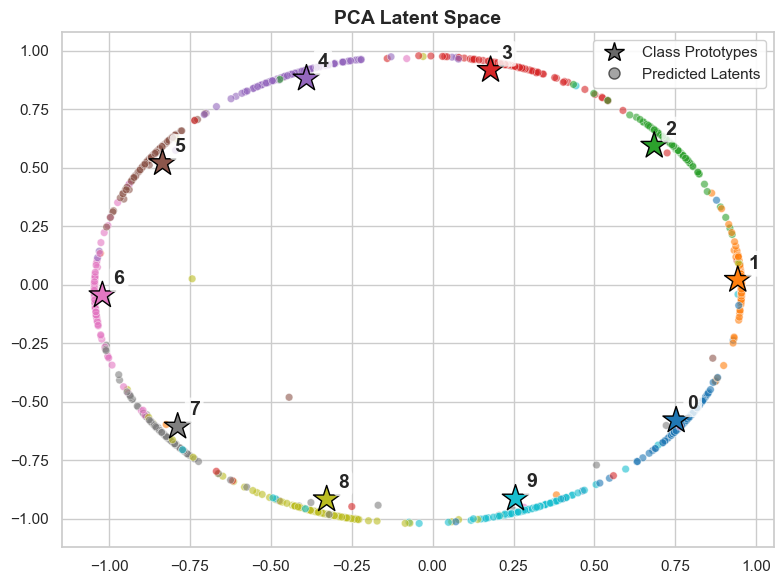

/Users/varan/miniconda3/envs/mnist-math/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


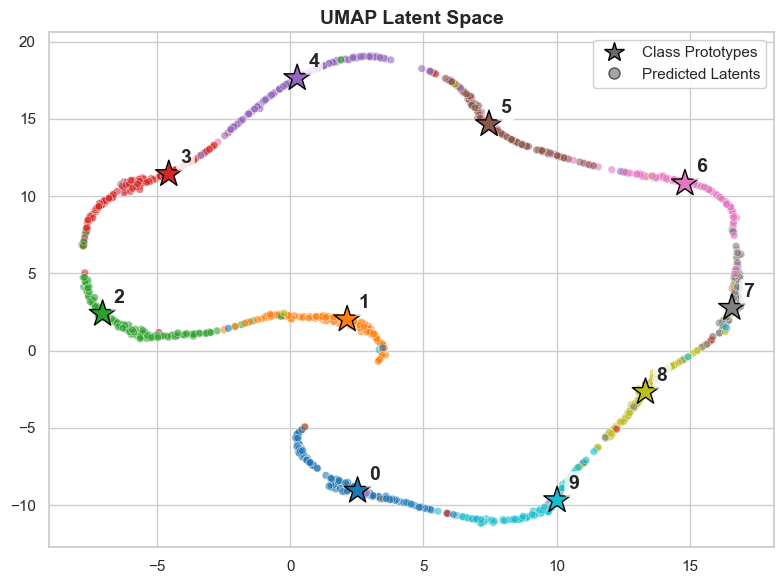

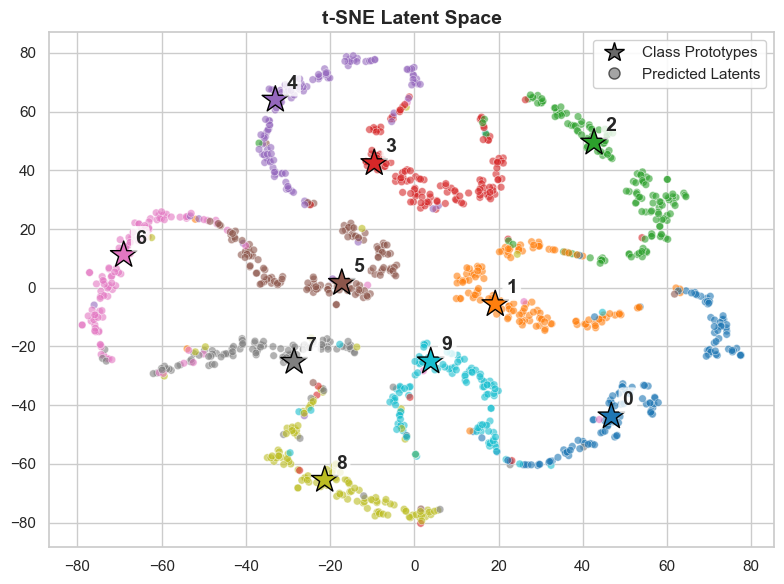

In [11]:

protos = get_class_prototypes(model, iid_loader, device)

plot_latent_manifolds(
    prototypes=protos,
    pred_latents=iid_preds,
    pred_labels=iid_tgt_labels,
    #FALSE IF WE ONLY WANT PROTOS, BUT LATENTS STILL USED TO CALC
    plot_predictions=True,   
    save_dir=SAVE_DIRECTORY,
    random_state=42,
)

### Note: t-SNE and UMAP are non-deterministic!!!
Use `random_state` to generate (ever-so-slightly) different plots

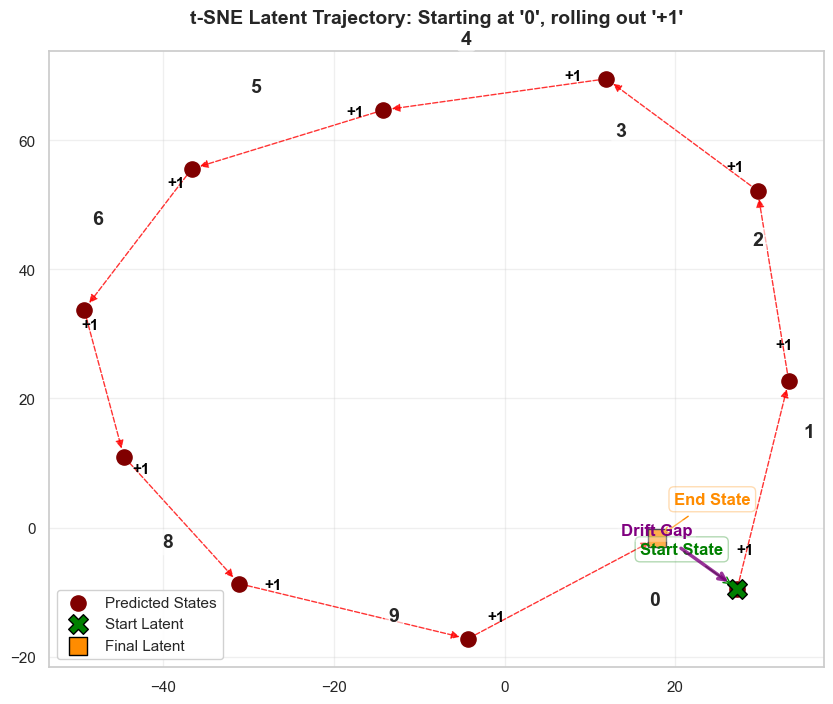

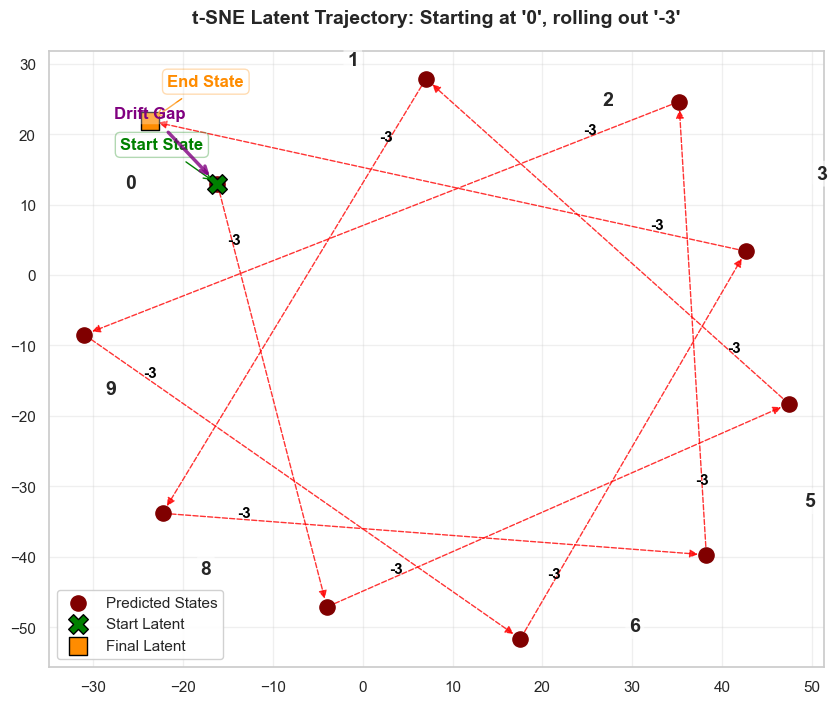

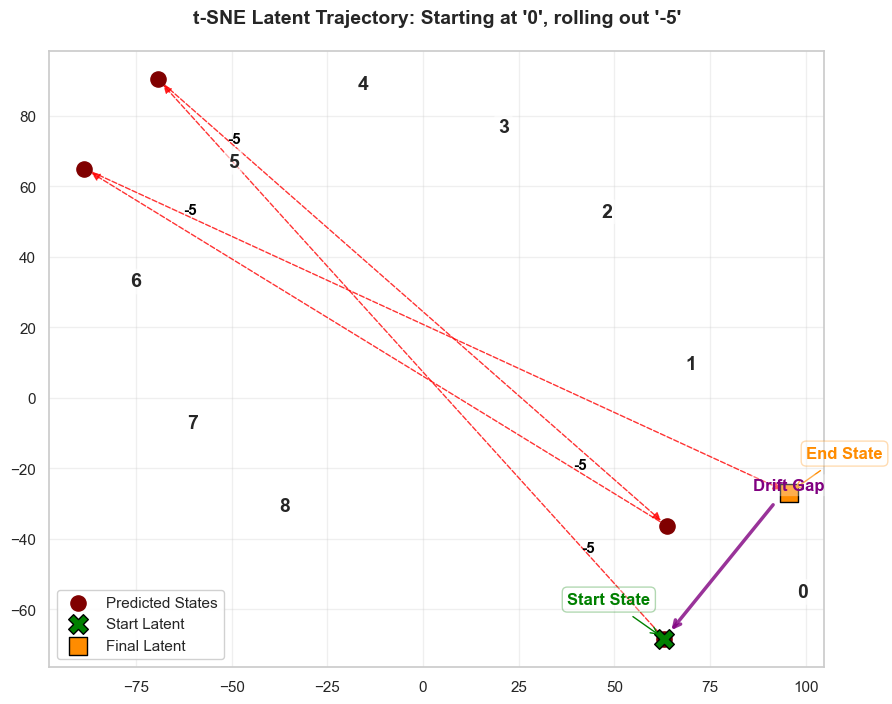

In [12]:
start_batch = next(iter(iid_loader))
start_idx = (start_batch["ctx_label"] == 0).nonzero(as_tuple=True)[0][0]
start_image = start_batch["ctx_img"][start_idx]

traj_plus_1 = generate_rollout_trajectory(
    model, start_image, op_val=+1.0, steps=10, device=device
)
plot_rollout_with_prototypes(
    protos,
    traj_plus_1,
    start_label=0,
    op_val="+1",
    use_pca=False,
    save_dir=SAVE_DIRECTORY,
    random_state=42,
)

traj_minus_3 = generate_rollout_trajectory(
    model, start_image, op_val=-3.0, steps=10, device=device
)
plot_rollout_with_prototypes(
    protos,
    traj_minus_3,
    start_label=0,
    op_val="-3",
    use_pca=False,
    save_dir=SAVE_DIRECTORY,
    random_state=42,
)

traj_minus_5 = generate_rollout_trajectory(
    model, start_image, op_val=-5.0, steps=4, device=device
)
plot_rollout_with_prototypes(
    protos,
    traj_minus_5,
    start_label=0,
    op_val="-5",
    use_pca=False,
    save_dir=SAVE_DIRECTORY,
    random_state=42,
)